# v5 — Dua resep training untuk AFL

**Pertanyaan.** Bisakah resep training MicroTransformer diubah sehingga AFL terdeteksi lebih baik daripada v3.1, tanpa
mengorbankan kelas lain?

| Varian | Yang diubah | Hipotesis (ditetapkan sebelum melihat hasil) |
|---|---|---|
| **5a. AFL rapat** | Window AFL di data **latih** digeser tiap 1 s (bukan 5 s), jadi 5× lebih banyak contoh AFL. Data uji tetap window standar 5 s | AFL recall/F1 naik dan Macro-F1 tidak turun. Petunjuk dari v3: resep v1 (stride AFL 1 s) mengalahkan revisi tanpa bias |
| **5b. Bobot lunak** | Bobot kelas di loss = akar dari bobot sekarang (AFL ±7×, bukan ±48×) | Model tidak lagi butuh bias AFL ekstrem (−4,5), dan Macro-F1 tidak turun |

**Agar adil.** Fold, seed latih (`2026 + 100·r + k`), hiperparameter, dan window uji sama persis dengan referensi v3/v3.1;
yang berubah hanya resep training. Bias kelas cross-fit grid −7…+3. Metrik window dan episode memakai kode v4.
Referensi = **v3.1**. Hasil utama = Δ Macro-F1 berpasangan, ditambah AFL F1, recall AFL per pasien, dan deteksi episode.

Biaya: 2 varian × 5 ulangan × 5 fold training (±75 menit GPU, bisa dilanjutkan). Tidak menyentuh paket produksi.
Logika ada di `latih.py`.

In [1]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import latih as L
cv = L.cv
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 30)


def fmt(v, nd=3):
    return f"{v[0]:.{nd}f} [{v[1]:.2f}–{v[2]:.2f}]"


def verdict(p):
    return "lebih baik" if p >= .95 else "lebih buruk" if p <= .05 else "tidak terbedakan"

## 1. Data latih AFL rapat

Kelas ekstraksi v2 hanya ada di dalam sel notebook v2, jadi `latih.py` menyalin logikanya. Salinan itu **dibuktikan
identik**: dengan stride standar, hasilnya harus sama bit demi bit dengan `../cache/dataset_v2_detector.npz`.

In [2]:
t0 = time.perf_counter()
counts = L.verify_and_build_dense()
print(f"✓ ekstraktor identik dengan v2 ({time.perf_counter() - t0:.0f}s)")
w_std = cv.class_weights(np.load(L.DATA_STD)["y"])
w_dense = cv.class_weights(np.load(L.DATA_DENSE)["y"])
display(pd.DataFrame({"window standar": counts["std"], "window AFL rapat": counts["dense"],
                      "bobot standar": w_std.round(2), "bobot lunak (akar)": (w_std ** .5).round(2),
                      "bobot pada data AFL rapat": w_dense.round(2)}, index=["Normal", "AFIB", "AFL"]))

✓ ekstraktor identik dengan v2 (47s)


,window standar,window AFL rapat,bobot standar,bobot lunak (akar),bobot pada data AFL rapat
Normal,99000,99000,0.56,0.75,0.57
AFIB,65826,65826,0.84,0.92,0.86
AFL,1152,5733,48.03,6.93,9.92


In [3]:
# Fungsi training v5 dengan bobot pangkat 1 harus identik dengan sihedaf_cv.train_dl (v3) pada seed yang sama.
z = np.load(L.DATA_STD)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tr = np.arange(len(z["y"])) % 5 != 0
te = np.flatnonzero(~tr)[:5000]
saved = L.HP["epochs"]
L.HP["epochs"] = 2
try:
    a = L.train_dl_weighted(z["X"][tr], z["M"][tr], z["y"][tr], weight_power=1.0, seed=7, device=dev)
finally:
    L.HP["epochs"] = saved
b = cv.train_dl("MicroTransformer", L.MODEL_KWARGS, z["X"][tr], z["M"][tr], z["y"][tr], epochs=2, batch_size=256,
                lr=1e-3, weight_decay=1e-4, seed=7, device=dev)
diff = np.abs(cv.predict_dl(a[0], z["X"][te], z["M"][te], a[1], a[2], dev)
              - cv.predict_dl(b[0], z["X"][te], z["M"][te], b[1], b[2], dev)).max()
print(f"✓ paritas training (2 epoch, 5.000 window): selisih maks {diff:.1e}" if diff < 1e-4 else f"⚠ selisih {diff:.1e}")

✓ paritas training (2 epoch, 5.000 window): selisih maks 0.0e+00


## 2. Training (2 varian × 5 ulangan × 5 fold)

OOF disimpan ke `../cache/oof_robust/detector_e30_r5_s2026/MicroTransformer_{varian}_r{ulangan}.npz`. Job yang sudah ada dilewati.

In [4]:
L.run_all_jobs()

0 job tersisa


## 3. Hasil

Semua baris: window uji detektor 50 Hz, rata-rata 5 ulangan, bias cross-fit grid −7…+3, CI 95% bootstrap pasien.

In [5]:
res = L.evaluate()
lab = res["labels"]
order = ["v1", "v31", "aflrapat", "bobotlunak"]
RES = pd.DataFrame([{"Varian": lab[k], **{m: fmt(res["rows"][k][m]) for m in ("Macro-F1", "AFL F1", "AFL P", "AFL R", "Normal R")},
                     "alarm AFL palsu/jam": fmt(res["episodes"][k]["alarm/jam"]),
                     "deteksi episode AFL": fmt(res["episodes"][k]["deteksi episode"], 2)} for k in order]).set_index("Varian")
display(RES)
ref_v3 = pd.read_csv(L.OOF_DIR / "ringkasan.csv").set_index("Model").loc["MicroTransformer +bias", "Macro-F1"]
assert ref_v3.startswith(f"{res['rows']['v31']['Macro-F1'][0]:.3f}"), ref_v3
print("✓ Referensi identik dengan v3/v3.1:", ref_v3)

PAIR = pd.DataFrame([{"Varian": lab[k], **{f"Δ {m}": f"{v[0]:+.3f} [{v[1]:+.2f}…{v[2]:+.2f}]" for m, v in res["pairs"][k].items()
                                            if m in ("Macro-F1", "AFL F1", "AFL R", "AFL P", "Normal R", "deteksi episode")},
                      "P(Δ MF1>0)": round(res["pairs"][k]["Macro-F1"][3], 2), "vonis": verdict(res["pairs"][k]["Macro-F1"][3])}
                     for k in ("v1", "aflrapat", "bobotlunak")]).set_index("Varian")
print("Δ berpasangan terhadap v3.1")
display(PAIR)

,Macro-F1,AFL F1,AFL P,AFL R,Normal R,alarm AFL palsu/jam,deteksi episode AFL
Varian,,,,,,,
"v1 (sebelum revisi), argmax",0.744 [0.64–0.81],0.399 [0.09–0.59],0.275 [0.05–0.46],0.728 [0.37–0.98],0.903 [0.82–0.95],5.101 [2.69–7.89],0.91 [0.73–1.00]
v3.1 referensi (resep v2/v3),0.832 [0.67–0.92],0.647 [0.17–0.89],0.715 [0.26–0.95],0.592 [0.13–0.91],0.924 [0.84–0.97],0.512 [0.10–1.07],0.74 [0.42–0.93]
5a: window AFL rapat (1 s) saat training,0.836 [0.66–0.92],0.660 [0.14–0.90],0.687 [0.19–0.92],0.637 [0.11–0.93],0.925 [0.85–0.97],0.619 [0.13–1.31],0.69 [0.35–0.90]
5b: bobot kelas lunak (akar),0.830 [0.68–0.89],0.637 [0.17–0.80],0.691 [0.21–0.93],0.595 [0.16–0.82],0.929 [0.86–0.97],0.542 [0.12–1.10],0.78 [0.52–0.95]


✓ Referensi identik dengan v3/v3.1: 0.832 [0.67–0.92]
Δ berpasangan terhadap v3.1


,Δ Macro-F1,Δ AFL F1,Δ AFL P,Δ AFL R,Δ Normal R,Δ deteksi episode,P(Δ MF1>0),vonis
Varian,,,,,,,,
"v1 (sebelum revisi), argmax",-0.088 [-0.16…-0.02],-0.249 [-0.47…-0.05],-0.440 [-0.65…-0.22],+0.136 [+0.06…+0.24],-0.020 [-0.03…-0.01],+0.169 [+0.03…+0.42],0.02,lebih buruk
5a: window AFL rapat (1 s) saat training,+0.004 [-0.02…+0.01],+0.013 [-0.07…+0.03],-0.028 [-0.07…-0.00],+0.045 [-0.06…+0.07],+0.002 [-0.00…+0.00],-0.046 [-0.09…-0.01],0.78,tidak terbedakan
5b: bobot kelas lunak (akar),-0.001 [-0.03…+0.02],-0.010 [-0.11…+0.04],-0.024 [-0.10…+0.01],+0.003 [-0.11…+0.06],+0.005 [+0.00…+0.01],+0.046 [+0.00…+0.15],0.48,tidak terbedakan


In [6]:
display(pd.DataFrame({lab[k]: {"bias AFIB (median)": v["median"][1], "bias AFL (median)": v["median"][2],
                               "bias AFL rentang": f"{v['min'][2]:.2f} … {v['max'][2]:.2f}"}
                      for k, v in res["bias"].items()}).T)
display(pd.DataFrame({lab[k]: v for k, v in res["fp"].items()}).T.round(0).rename(
    columns={"total": "AFL palsu (window/ulangan)", "pasien_lain": "di pasien tanpa AFL"}))
AFL = pd.DataFrame({lab[k]: res["afl_recall"][k] for k in order}, index=res["afl_patients"]).round(2)
AFL.index.name = "recall AFL per pasien"
display(AFL)

,bias AFIB (median),bias AFL (median),bias AFL rentang
v3.1 referensi (resep v2/v3),-0.75,-4.5,-5.50 … -4.00
5a: window AFL rapat (1 s) saat training,-0.75,-4.75,-7.00 … -4.25
5b: bobot kelas lunak (akar),-0.25,-2.25,-3.00 … -1.50


,AFL palsu (window/ulangan),di pasien tanpa AFL
"v1 (sebelum revisi), argmax",2240.0,1059.0
v3.1 referensi (resep v2/v3),274.0,25.0
5a: window AFL rapat (1 s) saat training,343.0,31.0
5b: bobot kelas lunak (akar),305.0,25.0


,"v1 (sebelum revisi), argmax",v3.1 referensi (resep v2/v3),5a: window AFL rapat (1 s) saat training,5b: bobot kelas lunak (akar)
recall AFL per pasien,,,,
04043,1.00,0.40,0.20,0.80
04908,1.00,0.92,0.78,0.92
04936,0.67,0.51,0.58,0.57
06426,0.73,0.17,0.15,0.30
07910,0.21,0.00,0.00,0.00
08215,0.04,0.00,0.00,0.00
08378,1.00,0.96,1.00,0.83


### Tanpa bias, dan kepekaan terhadap bias yang meleset

Di perangkat asli, proporsi AFL bisa berbeda dari AFDB, sehingga bias optimal ikut bergeser. Tabel pertama: hasil tanpa
bias sama sekali. Tabel kedua: Macro-F1 jika bias AFL hasil cross-fit meleset sebesar δ (log-prob). Kurva yang lebih datar
berarti model lebih tahan terhadap kalibrasi yang meleset.

In [7]:
display(pd.DataFrame({lab[k]: {m: fmt(v[m]) for m in ("Macro-F1", "AFL F1", "AFL P", "AFL R", "Normal R")}
                      for k, v in res["argmax_rows"].items()}).T)
for k, p in res["argmax_pairs"].items():
    print(f"Tanpa bias, {lab[k]} vs v3.1: Δ Macro-F1 {p[0]:+.3f} [{p[1]:+.2f}…{p[2]:+.2f}], P = {p[3]:.2f} → {verdict(p[3])}")
sens = res["bias_sensitivity"]
display(pd.DataFrame({lab[k]: v for k, v in sens["macro_f1"].items()},
                     index=[f"δ = {x:+.1f}" for x in sens["delta"]]).T.round(3))

,Macro-F1,AFL F1,AFL P,AFL R,Normal R
v3.1 referensi (resep v2/v3),0.717 [0.62–0.78],0.313 [0.04–0.48],0.201 [0.02–0.35],0.711 [0.31–0.98],0.895 [0.81–0.94]
5a: window AFL rapat (1 s) saat training,0.709 [0.62–0.77],0.294 [0.04–0.45],0.185 [0.02–0.31],0.731 [0.32–0.98],0.893 [0.80–0.94]
5b: bobot kelas lunak (akar),0.793 [0.64–0.85],0.521 [0.08–0.68],0.418 [0.05–0.58],0.696 [0.21–0.97],0.918 [0.84–0.96]


Tanpa bias, 5a: window AFL rapat (1 s) saat training vs v3.1: Δ Macro-F1 -0.007 [-0.01…-0.00], P = 0.01 → lebih buruk
Tanpa bias, 5b: bobot kelas lunak (akar) vs v3.1: Δ Macro-F1 +0.076 [+0.02…+0.10], P = 1.00 → lebih baik


,δ = -2.0,δ = -1.5,δ = -1.0,δ = -0.5,δ = +0.0,δ = +0.5,δ = +1.0,δ = +1.5,δ = +2.0
v3.1 referensi (resep v2/v3),0.779,0.799,0.817,0.825,0.832,0.830,0.820,0.808,0.791
5a: window AFL rapat (1 s) saat training,0.772,0.789,0.802,0.830,0.836,0.831,0.821,0.808,0.792
5b: bobot kelas lunak (akar),0.770,0.779,0.800,0.827,0.830,0.838,0.827,0.811,0.791


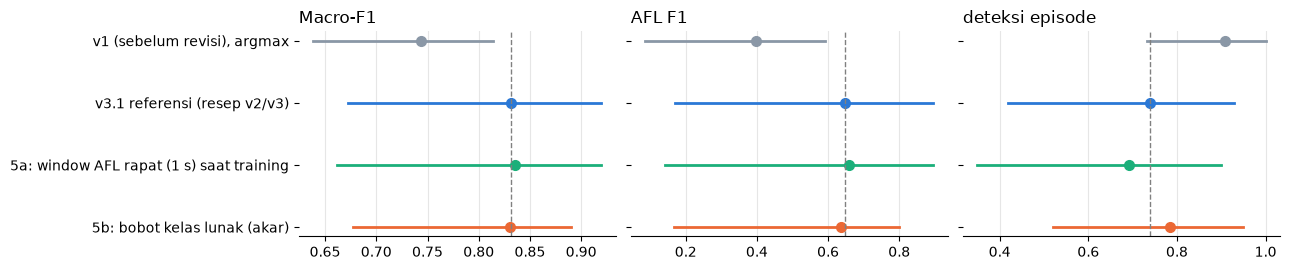

In [8]:
COLOR = {"v1": "#8A97A6", "v31": "#2a78d6", "aflrapat": "#1baf7a", "bobotlunak": "#eb6834"}
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8), sharey=True)
for ax, (m, src) in zip(axes, (("Macro-F1", "rows"), ("AFL F1", "rows"), ("deteksi episode", "episodes"))):
    for i, k in enumerate(order):
        pt, lo, hi = res[src][k][m]
        ax.plot([lo, hi], [i, i], color=COLOR[k], lw=2); ax.plot(pt, i, "o", color=COLOR[k], ms=7)
    ax.axvline(res[src]["v31"][m][0], color="0.5", lw=1, ls="--")
    ax.set_title(m, loc="left"); ax.grid(axis="x", color="0.9"); ax.set_axisbelow(True)
    for s_ in ("top", "right", "left"):
        ax.spines[s_].set_visible(False)
axes[0].set_yticks(range(len(order)), [lab[k] for k in order]); axes[0].invert_yaxis()
plt.tight_layout(); plt.show()

In [9]:
L.CACHE_OUT.mkdir(parents=True, exist_ok=True)
(L.CACHE_OUT / "ringkasan.json").write_text(json.dumps(res, indent=1, ensure_ascii=False))
for k in ("aflrapat", "bobotlunak"):
    p = res["pairs"][k]
    print(f"{lab[k]:<45} Δ Macro-F1 {p['Macro-F1'][0]:+.3f} (P={p['Macro-F1'][3]:.2f}, {verdict(p['Macro-F1'][3])}) | "
          f"Δ AFL F1 {p['AFL F1'][0]:+.3f} (P={p['AFL F1'][3]:.2f}) | Δ AFL R {p['AFL R'][0]:+.3f}")
print(f"Ringkasan → {L.CACHE_OUT.relative_to(L.REPO)}/ringkasan.json")

5a: window AFL rapat (1 s) saat training      Δ Macro-F1 +0.004 (P=0.78, tidak terbedakan) | Δ AFL F1 +0.013 (P=0.77) | Δ AFL R +0.045
5b: bobot kelas lunak (akar)                  Δ Macro-F1 -0.001 (P=0.48, tidak terbedakan) | Δ AFL F1 -0.010 (P=0.41) | Δ AFL R +0.003
Ringkasan → cache/v5/ringkasan.json


## 4. Kesimpulan

**Tidak ada resep yang lebih baik dari v3.1. Paket produksi tetap v3.1; v5 tidak dikemas.**

- **5a, window AFL rapat (1 s) saat training: hipotesis ditolak.**
  - Setara dalam Macro-F1 (Δ +0,004 [−0,02…+0,01], P = 0,78) dan AFL F1 (Δ +0,013).
  - Deteksi episode AFL turun secara konsisten (Δ −0,05 [−0,09…−0,01]), dan AFL palsu bertambah (274 → 343 window per ulangan).
  - Bias AFL yang dibutuhkan malah lebih ekstrem (median −4,75, sebagian fold menyentuh batas grid −7).
  - Petunjuk dari v3 (resep v1 dengan stride rapat lebih baik dari revisi tanpa bias) **bukan** berasal dari kepadatan data AFL.
- **5b, bobot kelas lunak (akar): hipotesis terbukti.**
  - Setara dalam Macro-F1 (Δ −0,001, P = 0,48).
  - Bias AFL yang dibutuhkan setengahnya (median −2,25 vs −4,5).
  - Tanpa bias sama sekali jauh lebih baik dari v3.1 (Macro-F1 0,793 vs 0,717, P = 1,00).
  - Tetapi jika bias terpasang lalu meleset (δ ±0,5…±2), penurunannya sama dengan v3.1, jadi tidak lebih tahan kalibrasi meleset.
- **Keputusan.**
  - Model produksi tidak diganti.
  - Bobot lunak dijadikan resep bawaan untuk model **baru** (setara, koreksi bias tidak ekstrem).
- **Untuk proyek.** Semua tuas berbasis interval RR (arsitektur, bias, smoothing, ensemble, kepadatan AFL, bobot kelas) berhenti di
  sekitar Macro-F1 0,83, dan 07910 serta 08215 tidak pernah terdeteksi. Batasnya ada pada informasi input.

**Langkah berikutnya (v6):** cabang EKG mentah 50 Hz (mulai dari MiniRocket, lalu CNN dua cabang EKG + RR, bobot lunak),
atau data AFL tambahan dari basis data lain.